# 01 · Calibración de la cámara

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StevenFAP1815/project-reconstruction-3d/blob/main/notebooks/01_calibration.ipynb)

Este notebook calcula los **intrínsecos** del teléfono a partir de las fotos
del tablero de calibración (criterio 3 de la rúbrica):

- **Matriz K**: focal en píxeles (fx, fy) y centro óptico (cx, cy).
- **Distorsión**: coeficientes (k1, k2, p1, p2, k3) de la lente.
- **Error de reproyección RMS**: distancia media, en píxeles, entre las
  esquinas detectadas y las que predice el modelo (referencia ≤ 0,5 px).

**Modelo pinhole.** Un punto 3D (X, Y, Z), expresado en coordenadas de la
cámara, se proyecta en el píxel u = fx·X/Z + cx, v = fy·Y/Z + cy. La lente
añade una distorsión que curva las rectas, sobre todo cerca de los bordes.

**Requisitos previos**

1. `00_setup_colab.ipynb` ejecutado al menos una vez.
2. `calibration.zip` subido a `Mi unidad/project-reconstruction-3d/data/zips/`.
3. El tamaño del cuadro medido con regla (ver `docs/calibration/README.md`).

No necesita GPU.

## 1. Entorno

In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/StevenFAP1815/project-reconstruction-3d.git"
REPO_DIR = Path("/content/project-reconstruction-3d")

if REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))

# Python importa cada módulo una sola vez por sesión. Si esta sesión ya había
# cargado recon3d (una ejecución anterior), se descarta para que el siguiente
# import lea el código recién descargado y no una versión antigua en memoria.
for module in [name for name in sys.modules if name == "recon3d" or name.startswith("recon3d.")]:
    del sys.modules[module]

COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()
print("Código del repositorio en el commit", COMMIT)

Código del repositorio en el commit cb0849f


In [3]:
from recon3d.dataset import extract_object_zip
from recon3d.paths import get_paths
from recon3d.reproducibility import set_seed

SEED = 42
set_seed(SEED)

paths = get_paths()
paths.create()

LOCAL_CALIBRATION = Path("/content/data/calibration")
images = extract_object_zip(paths.data_zip("calibration"), LOCAL_CALIBRATION)
print(f"{len(images)} fotos de calibración en {LOCAL_CALIBRATION}")

49 fotos de calibración en /content/data/calibration


## 2. Parámetros

`SQUARE_MM` es el tamaño real de un cuadro del tablero en la pantalla:
ancho de los 10 cuadros de una fila, medido con regla, dividido entre 10.

In [4]:
PATTERN = (9, 6)               # esquinas internas (columnas, filas)
SQUARE_MM = 22.0               # p. ej. 21.2  <- completar con la medida real
EXPECTED_SIZE = (3000, 4000)   # mismo tamaño que las fotos de los objetos (vertical)
FOCAL_35MM_EXIF = 24           # focal equivalente registrada en el EXIF

assert SQUARE_MM is not None, "Completar SQUARE_MM con la medida tomada con regla"

## 3. Detección de las esquinas

Para cada foto se prueban tres intentos, del más fiable al último recurso:

1. `sb_reduced`: detector SB sobre la foto reducida a 2000 px. A 12 MP la
   cámara capta la rejilla de píxeles de la pantalla (moiré), que confunde al
   detector; en la foto reducida ese patrón desaparece.
2. `sb_full`: detector SB sobre la foto completa.
3. `classic_reduced`: detector clásico sobre la foto reducida.

En todos los casos las esquinas se refinan con precisión subpíxel sobre la
foto completa. Las fotos donde el tablero no aparece completo se descartan.

In [5]:
import time
from collections import Counter

from recon3d.calibration import detect_corners

start = time.perf_counter()
detections = detect_corners(images, PATTERN, expected_size=EXPECTED_SIZE)

print(f"Tablero detectado: {len(detections.corners)} de {len(images)} fotos")
print("Intento que funcionó:", dict(Counter(detections.methods)))
for path in detections.rejected:
    print(f"  descartada: {path.name}")

Tablero detectado: 42 de 49 fotos
Intento que funcionó: {'sb_reduced': 38, 'classic_reduced': 4}
  descartada: IMG_20261113_181349.jpg
  descartada: IMG_20261113_181410_1.jpg
  descartada: IMG_20261113_181411_1.jpg
  descartada: IMG_20261113_181444.jpg
  descartada: IMG_20261113_181444_2.jpg
  descartada: IMG_20261113_181457.jpg
  descartada: IMG_20261113_181501.jpg


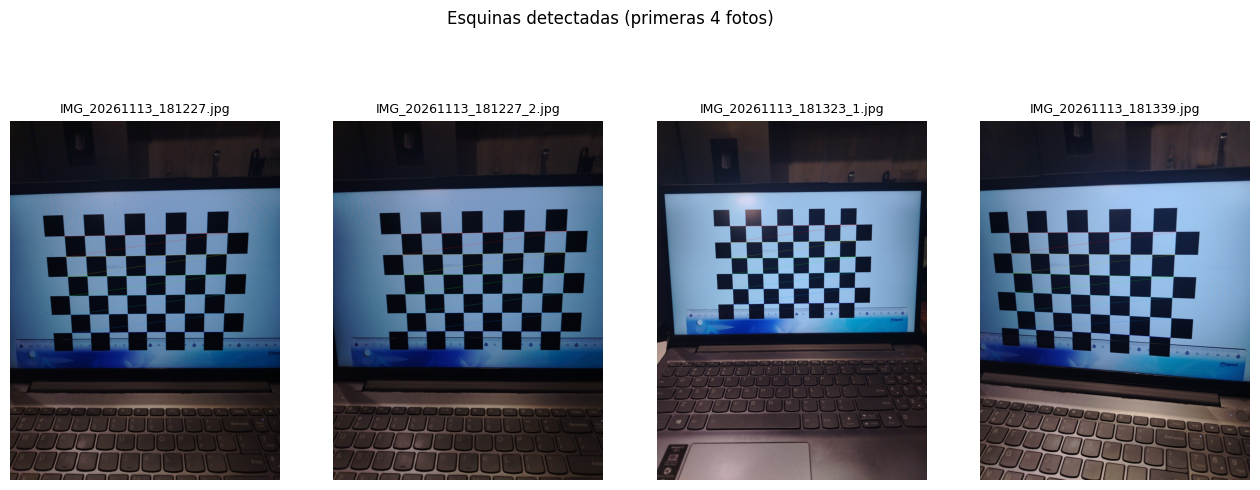

In [6]:
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 6))
for ax, path, corners in zip(axes, detections.image_paths, detections.corners):
    image = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    cv2.drawChessboardCorners(image, PATTERN, corners.reshape(-1, 1, 2), True)
    ax.imshow(image)
    ax.set_title(path.name, fontsize=9)
    ax.axis("off")
fig.suptitle("Esquinas detectadas (primeras 4 fotos)")
plt.show()

### Cobertura del encuadre

La distorsión es mayor cerca de los bordes de la foto. Si las esquinas solo
cubren el centro, la distorsión queda mal estimada.

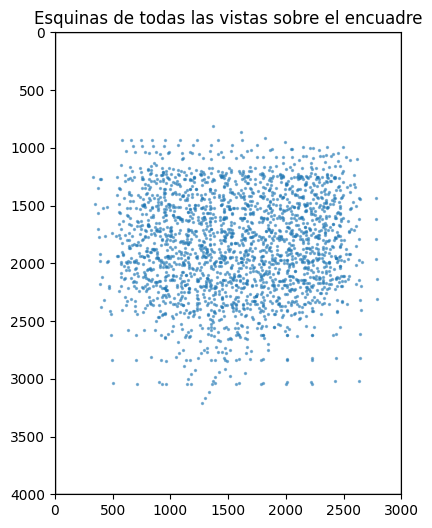

In [7]:
import numpy as np

all_corners = np.vstack(detections.corners)
width, height = detections.image_size

fig, ax = plt.subplots(figsize=(4.5, 6))
ax.scatter(all_corners[:, 0], all_corners[:, 1], s=2, alpha=0.5)
ax.add_patch(plt.Rectangle((0, 0), width, height, fill=False, color="black"))
ax.set_xlim(0, width)
ax.set_ylim(height, 0)
ax.set_aspect("equal")
ax.set_title("Esquinas de todas las vistas sobre el encuadre")
plt.show()

## 4. Calibración

In [8]:
from recon3d.calibration import calibrate, focal_px_from_35mm

# Por defecto: k3 fijo a 0 y exclusión de vistas con error > 2 x la mediana.
result = calibrate(detections, SQUARE_MM, PATTERN)

np.set_printoptions(precision=3, suppress=True)
print("K =\n", result.camera_matrix)
print("Distorsión (k1, k2, p1, p2, k3) =", result.dist_coeffs)
print(f"k3 fijo: {result.fix_k3} | umbral de exclusión: {result.outlier_ratio} x mediana")
print(f"Vistas usadas: {len(result.image_names)} | excluidas automáticamente: {len(result.excluded_views)}")
for name, error in result.excluded_views.items():
    print(f"  excluida: {name} (error {error:.2f} px)")
print(f"Error de reproyección RMS = {result.rms_px:.3f} px  (referencia ≤ 0,5 px)")

expected_fx = focal_px_from_35mm(FOCAL_35MM_EXIF, detections.image_size)
print(f"fx calibrado = {result.camera_matrix[0, 0]:.0f} px | "
      f"fx esperado según el EXIF ≈ {expected_fx:.0f} px")

K =
 [[2851.926    0.    1504.546]
 [   0.    2851.658 2010.97 ]
 [   0.       0.       1.   ]]
Distorsión (k1, k2, p1, p2, k3) = [ 0.18  -0.549  0.001 -0.     0.   ]
k3 fijo: True | umbral de exclusión: 2.0 x mediana
Vistas usadas: 40 | excluidas automáticamente: 2
  excluida: IMG_20261113_181502_2.jpg (error 2.57 px)
  excluida: IMG_20261113_181529.jpg (error 1.59 px)
Error de reproyección RMS = 0.808 px  (referencia ≤ 0,5 px)
fx calibrado = 2852 px | fx esperado según el EXIF ≈ 2774 px


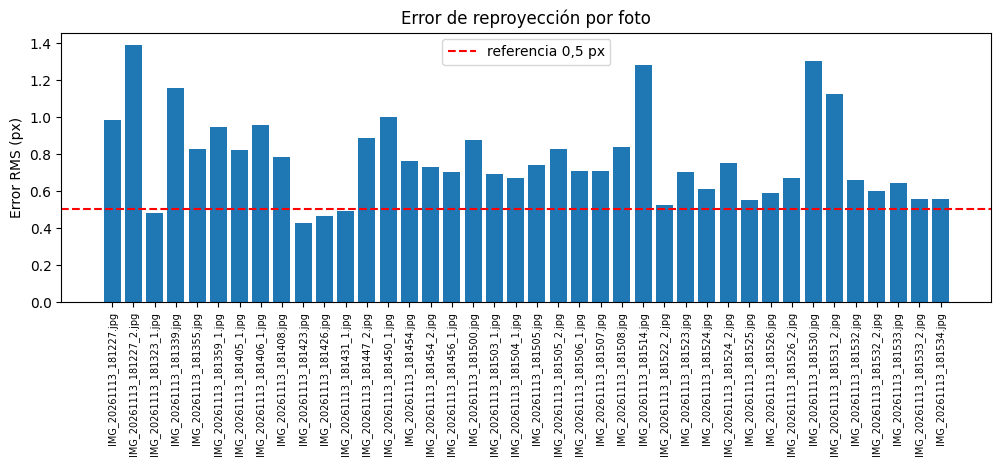

In [9]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(range(len(result.per_view_errors_px)), result.per_view_errors_px)
ax.axhline(0.5, color="red", linestyle="--", label="referencia 0,5 px")
ax.set_xticks(range(len(result.image_names)))
ax.set_xticklabels(result.image_names, rotation=90, fontsize=7)
ax.set_ylabel("Error RMS (px)")
ax.set_title("Error de reproyección por foto")
ax.legend()
plt.show()

### (Opcional) Excluir fotos con error alto

Una foto con error muy superior al resto suele estar movida o tener reflejos.
Para excluirla, se añade su nombre a `EXCLUDE` y se vuelve a ejecutar esta
celda. Las exclusiones se documentan en el informe.

In [10]:
from recon3d.calibration import Detections

EXCLUDE = []  # p. ej. ["IMG_20261114_101530.jpg"]

if EXCLUDE:
    keep = [i for i, p in enumerate(detections.image_paths) if p.name not in EXCLUDE]
    detections = Detections(
        image_size=detections.image_size,
        image_paths=[detections.image_paths[i] for i in keep],
        corners=[detections.corners[i] for i in keep],
        methods=[detections.methods[i] for i in keep],
        rejected=detections.rejected,
    )
    result = calibrate(detections, SQUARE_MM, PATTERN)
    print(f"Recalibrado con {len(keep)} fotos: RMS = {result.rms_px:.3f} px")

## 5. Efecto de la corrección de distorsión

A la izquierda, la foto original; a la derecha, corregida con K y los
coeficientes de distorsión. Las líneas del tablero cercanas a los bordes deben
verse más rectas.

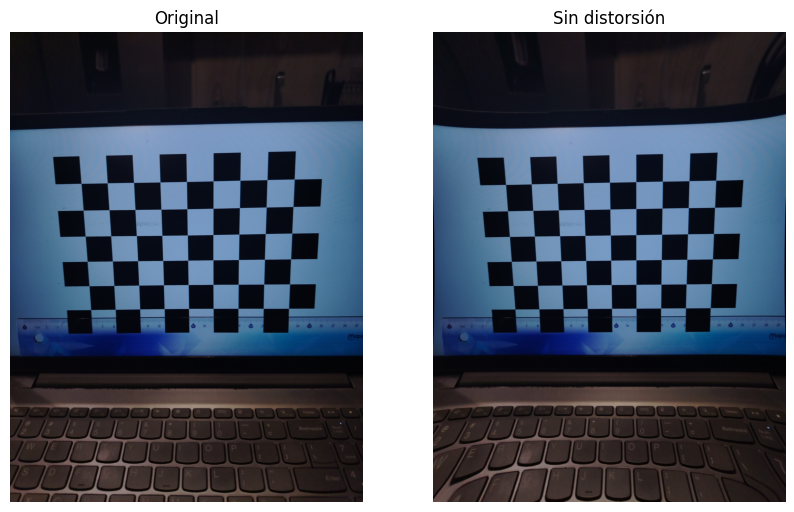

In [11]:
sample = detections.image_paths[0]
original = cv2.cvtColor(cv2.imread(str(sample)), cv2.COLOR_BGR2RGB)
undistorted = cv2.undistort(original, result.camera_matrix, result.dist_coeffs)

fig, axes = plt.subplots(1, 2, figsize=(10, 7))
for ax, image, title in zip(axes, [original, undistorted], ["Original", "Sin distorsión"]):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 6. Guardar resultados

Se guardan en `results/calibration/` de Drive:

- `calibration.json`: K, distorsión, RMS y error por foto. Lo leen los
  notebooks siguientes.
- `meta.json`: registro de la corrida (fotos, tiempo, versiones, semilla).

In [12]:
from recon3d.calibration import save_calibration
from recon3d.results import write_meta

runtime_s = time.perf_counter() - start
calibration_path = save_calibration(result, paths.calibration_results / "calibration.json")
meta_path = write_meta(
    paths.calibration_results,
    object_name="calibration",
    method="opencv-checkerboard",
    n_images=len(images),
    n_registered=len(result.image_names),
    runtime_s=runtime_s,
    seed=SEED,
    extra={
        "rms_px": round(result.rms_px, 4),
        "square_mm": SQUARE_MM,
        "pattern_size": list(PATTERN),
        "n_detected": len(detections.corners),
        "fix_k3": result.fix_k3,
        "outlier_ratio": result.outlier_ratio,
        "auto_excluded": {k: round(v, 4) for k, v in result.excluded_views.items()},
        "excluded": EXCLUDE,
    },
)
print(calibration_path)
print(meta_path)

/content/drive/MyDrive/project-reconstruction-3d/results/calibration/calibration.json
/content/drive/MyDrive/project-reconstruction-3d/results/calibration/meta.json


## Siguiente paso

- Descargar `results/calibration/` de Drive y copiarlo en `results/calibration/`
  del repositorio local, para versionar `calibration.json` y `meta.json`.
- En el notebook de SfM se compararán estos intrínsecos con los que COLMAP
  estima por su cuenta (autocalibración), como pide la rúbrica.